In [20]:
### Part 1: Prices

#1.1 Loading and merging price files
import pandas as pd
aurx_df = pd.read_csv(r"C:\Users\User\Desktop\MFDA 2026.2028\Data Processing in Python (JEM207)\Midterm\data\prices\AURX.csv")
nova_df = pd.read_csv(r"C:\Users\User\Desktop\MFDA 2026.2028\Data Processing in Python (JEM207)\Midterm\data\prices\NOVA.csv")
zeph_df = pd.read_csv(r"C:\Users\User\Desktop\MFDA 2026.2028\Data Processing in Python (JEM207)\Midterm\data\prices\ZEPH.csv")
display(aurx_df.head())
display(nova_df.head())
display(zeph_df.head())

aurx_df["Ticker"] = "AURX"
nova_df["Ticker"] = "NOVA"
zeph_df["Ticker"] = "ZEPH"

dfs = [aurx_df, nova_df, zeph_df]
coins_df = pd.concat(dfs)

coins_df["Date"] = pd.to_datetime(coins_df["Date"])
coins_df = coins_df.set_index("Date")
coins_df




,Date,Open,High,Low,Close,Volume
0,2024-01-01,42164.26,43960.10,41962.16,43082.83,41339
1,2024-01-02,42948.12,42995.24,41423.30,41859.96,25884
2,2024-01-03,41937.18,41937.22,40697.01,41306.32,20416
3,2024-01-04,41407.01,43181.00,40596.18,42817.69,20191
4,2024-01-05,42890.54,44310.84,42648.29,43846.18,30714


,Date,Open,High,Low,Close,Volume
0,2024-01-01,2298.57,2331.82,2291.62,2315.69,129266
1,2024-01-02,2309.76,2350.91,2277.67,2308.36,148306
2,2024-01-03,2308.35,2332.79,2282.75,2289.62,266970
3,2024-01-04,2289.38,2320.09,2287.28,2308.59,264204
4,2024-01-05,2302.82,2342.53,2277.55,2292.09,128575


,Date,Open,High,Low,Close,Volume
0,2024-01-01,95.05,95.69,93.04,94.11,2144777
1,2024-01-02,93.90,94.03,92.38,93.69,1570267
2,2024-01-03,93.70,100.22,92.82,96.91,2695390
3,2024-01-04,96.90,103.13,95.95,99.05,4045717
4,2024-01-05,99.25,99.98,89.71,91.81,4988231


,Open,High,Low,Close,Volume,Ticker
Date,,,,,,
2024-01-01,42164.26,43960.10,41962.16,43082.83,41339,AURX
2024-01-02,42948.12,42995.24,41423.30,41859.96,25884,AURX
2024-01-03,41937.18,41937.22,40697.01,41306.32,20416,AURX
2024-01-04,41407.01,43181.00,40596.18,42817.69,20191,AURX
2024-01-05,42890.54,44310.84,42648.29,43846.18,30714,AURX
...,...,...,...,...,...,...
2025-12-27,181.38,191.90,180.50,191.11,4470581,ZEPH
2025-12-28,191.07,191.51,184.86,188.22,2797540,ZEPH
2025-12-29,188.40,195.44,187.10,189.97,3627945,ZEPH


In [22]:
#1.2 Highest, lowest price + date
for ticker in ["AURX", "NOVA", "ZEPH"]:
    coin = coins_df[coins_df["Ticker"] == ticker]
    print(ticker, coin["Close"].max(), coin["Close"].idxmax(), 
          coin["Close"].min(), coin["Close"].idxmin())

AURX 70734.5 2025-07-02 00:00:00 25402.79 2024-05-10 00:00:00
NOVA 10243.17 2025-12-22 00:00:00 2237.75 2024-07-13 00:00:00
ZEPH 251.24 2025-11-26 00:00:00 43.26 2024-11-23 00:00:00


In [28]:
#1.3 Daily % return of Close for each coin
coins_df["Return"] = coins_df.groupby("Ticker")["Close"].pct_change()
coins_df.groupby("Ticker")["Return"].agg(["mean", "std", "min", "max"])

,mean,std,min,max
Ticker,,,,
AURX,0.000683,0.030209,-0.124684,0.151234
NOVA,0.002631,0.038504,-0.112418,0.253877
ZEPH,0.002312,0.054386,-0.275275,0.298783


In [31]:
#1.4 Average close price per coin
for ticker in ["AURX", "NOVA", "ZEPH"]:
    coin = coins_df[coins_df["Ticker"] == ticker]
    monthly = coin["Close"].resample("ME").mean()
    print(ticker, monthly.max(), monthly.idxmax())

AURX 63652.22677419355 2025-07-31 00:00:00
NOVA 9520.216129032258 2025-12-31 00:00:00
ZEPH 210.10399999999998 2025-11-30 00:00:00


<Axes: xlabel='Date'>

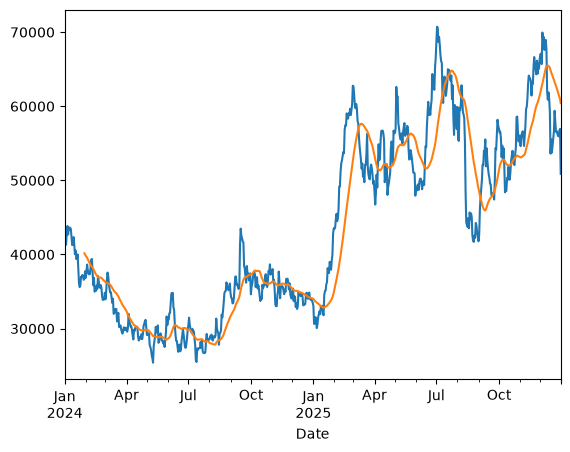

In [33]:
#1.5 Plotting Close of AURX with 30-day rolling mean
aurx = coins_df[coins_df["Ticker"] == "AURX"]
aurx["Close"].plot()
aurx["Close"].rolling(30).mean().plot()

In [41]:
### Part 2: Coin Metadata

#2.1 Loading and finding missing values
meta_df = pd.read_csv(r"C:\Users\User\Desktop\MFDA 2026.2028\Data Processing in Python (JEM207)\Midterm\data\coins\coins_no_subcategory.csv")
meta_df.head()
meta_df.isna().sum()

meta_df["listed"] = pd.to_datetime(meta_df["listed"])
meta_df = meta_df.dropna(subset=["listed"])
meta_df.isna().sum()

ticker      0
name        0
category    0
listed      0
founded     0
dtype: int64

In [44]:
#2.2 Youngest and Oldest Coin
meta_df.loc[meta_df["listed"].idxmin()]
meta_df.loc[meta_df["listed"].idxmax()]

ticker                     ELYO
name                     Elyora
category                 Gaming
listed      2024-08-12 00:00:00
founded                    2022
Name: 35, dtype: object

In [47]:
#2.3 Join with 2nd table
sub_df = pd.read_csv(r"C:\Users\User\Desktop\MFDA 2026.2028\Data Processing in Python (JEM207)\Midterm\data\coins\coins_subcategory.csv")
sub_df.head()

merged_df = meta_df.merge(sub_df, on = "ticker")
merged_df.head()
merged_df["subcategory"].value_counts()

subcategory
Algorithmic         4
Smart contracts     4
Metaverse           4
DEX                 3
Private payments    3
Derivatives         3
Bridge              2
Compute             2
Scaling             2
Payments            2
Crypto-backed       1
Lending             1
Oracle              1
Mixers              1
Play-to-earn        1
Name: count, dtype: int64

In [49]:
### Part 3: NumPy

#3.1 Generating random numbers 
import numpy as np

rng = np.random.default_rng(42)
normal_sample = rng.normal(0, 1, 500)
uniform_sample = rng.uniform(0, 1, 500)
print("Normal", normal_sample.mean(), normal_sample.std())
print("Uniform", uniform_sample.mean(), uniform_sample.std())

Normal -0.013126150466933863 0.9589737047166969
Uniform 0.4981182895007331 0.2950127203893292


Text(0.5, 1.0, 'Uniform')

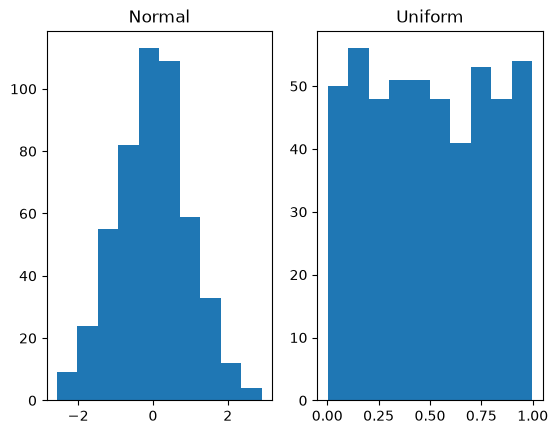

In [51]:
#3.2 Histogram
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2)
axes[0].hist(normal_sample)
axes[0].set_title("Normal")
axes[1].hist(uniform_sample)
axes[1].set_title("Uniform")

In [52]:
### Bonus 

#B.1 
fib = [0, 1]
for i in range(13):
    fib.append(fib[-1] + fib[-2])
print(fib)

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]


In [53]:
#B.2
total = 0
for x in fib:
    if x % 2 == 0:
        total = total + x
print(total)

188
